## Практична

## завдання 1

In [1]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

wine = load_wine()

df = pd.DataFrame(data=wine.data, columns=wine.feature_names)
df['target'] = wine.target

X = df.drop('target', axis=1)
print(f"Розмір матриці ознак: {X.shape}")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

df_scaled = pd.DataFrame(X_scaled, columns=wine.feature_names)

Розмір матриці ознак: (178, 13)


## завдання 2

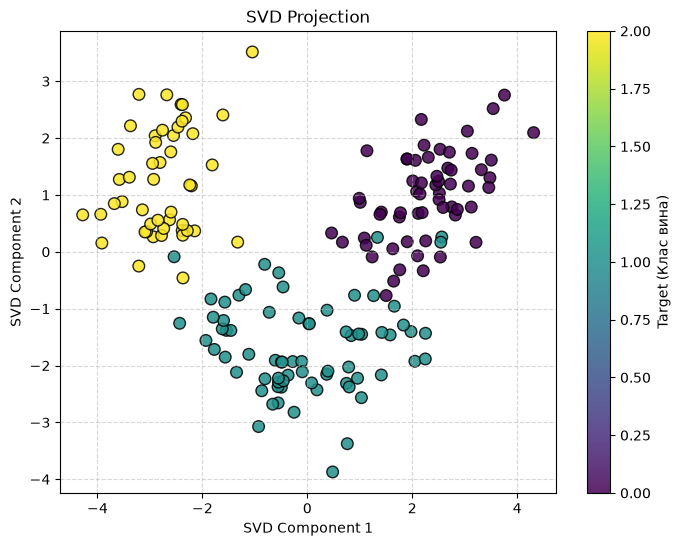

In [2]:
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=2, random_state=42)

X_svd = svd.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_svd[:, 0], 
    X_svd[:, 1], 
    c=df['target'], 
    cmap='viridis', 
    edgecolor='k', 
    s=70, 
    alpha=0.85
)

plt.xlabel('SVD Component 1')
plt.ylabel('SVD Component 2')
plt.title('SVD Projection')
plt.colorbar(scatter, label='Target (Клас вина)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

## завдання 3

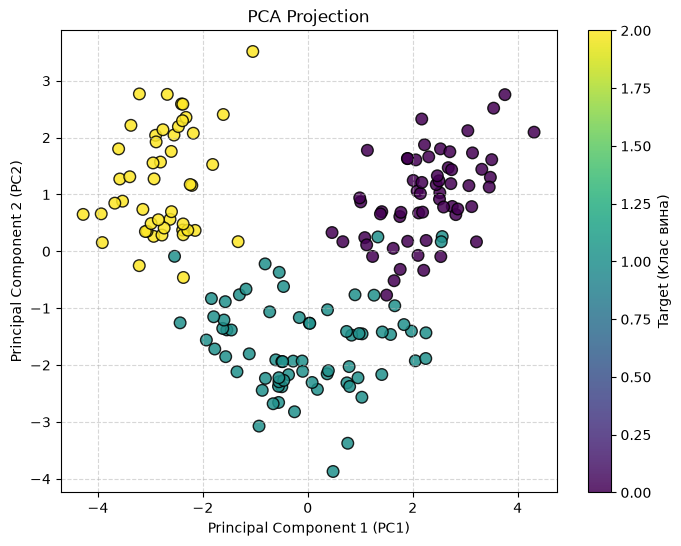

In [3]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0], 
    X_pca[:, 1], 
    c=df['target'], 
    cmap='viridis', 
    edgecolor='k', 
    s=70, 
    alpha=0.85
)

plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('PCA Projection')
plt.colorbar(scatter, label='Target (Клас вина)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

## завдання 4

Частка поясненої дисперсії для PC1 та PC2: [0.36198848 0.1920749 ]
Сумарна пояснена дисперсія (2 компоненти): 55.41%


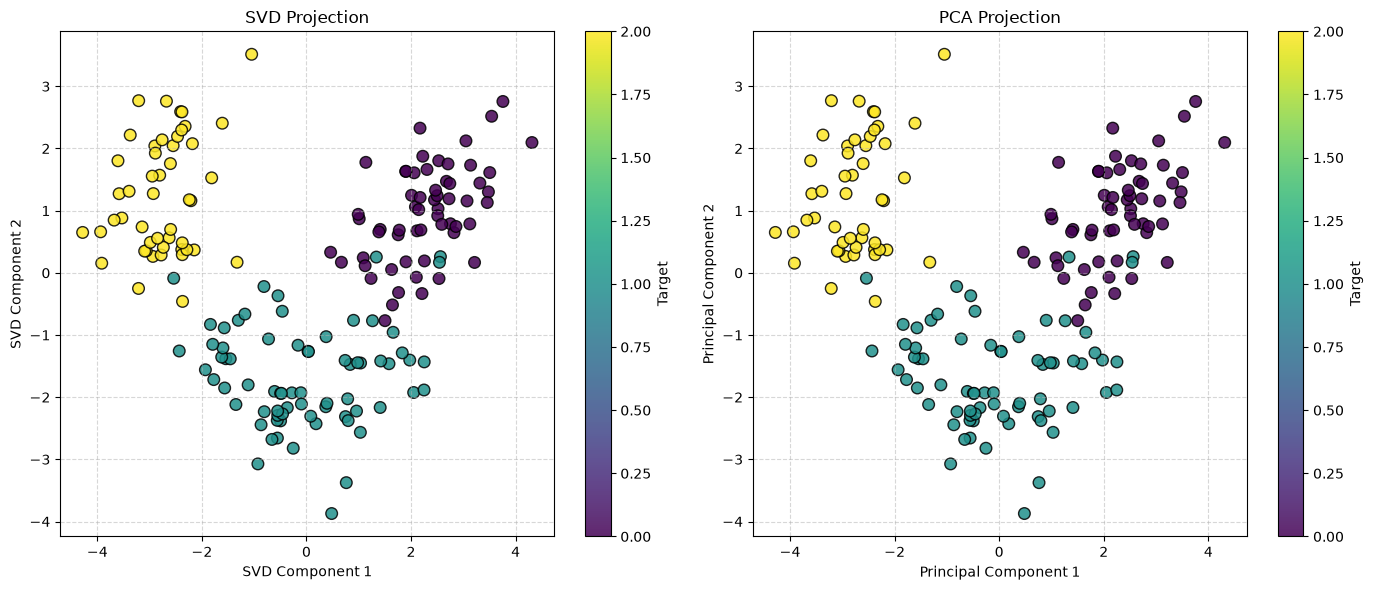

In [4]:
explained_var = pca.explained_variance_ratio_
print(f"Частка поясненої дисперсії для PC1 та PC2: {explained_var}")
print(f"Сумарна пояснена дисперсія (2 компоненти): {explained_var.sum():.2%}")

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
scatter_svd = plt.scatter(
    X_svd[:, 0], 
    X_svd[:, 1], 
    c=df['target'], 
    cmap='viridis', 
    edgecolor='k', 
    s=70, 
    alpha=0.85
)
plt.xlabel('SVD Component 1')
plt.ylabel('SVD Component 2')
plt.title('SVD Projection')
plt.colorbar(scatter_svd, label='Target')
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
scatter_pca = plt.scatter(
    X_pca[:, 0], 
    X_pca[:, 1], 
    c=df['target'], 
    cmap='viridis', 
    edgecolor='k', 
    s=70, 
    alpha=0.85
)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA Projection')
plt.colorbar(scatter_pca, label='Target')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('dimensionality_reduction_comparison.png', dpi=300)
plt.show()